# Tutorial: Loading a Model with Multiple Series and Faults using JSON I/O

This tutorial demonstrates how to load a geological model with multiple series and faults using GemPy's JSON I/O functionality.
The model consists of two layers (rock1, rock2) and a fault that offsets them.

**Note:** This notebook is configured to use PyTorch as the backend.

In [27]:
# Import necessary libraries
import matplotlib
# matplotlib.use('Agg')  # Use non-interactive backend (uncomment if needed)
import gempy as gp
import gempy_viewer as gpv
import numpy as np
import json
from pathlib import Path
import matplotlib.pyplot as plt
from gempy_engine.core.data.stack_relation_type import StackRelationType
from gempy.modules.json_io.json_operations import JsonIO
from gempy.core.data.gempy_engine_config import GemPyEngineConfig
from gempy_engine.config import AvailableBackends
from datetime import datetime

In [28]:
# Define the model data
model_data = {
    "metadata": {
        "name": "Multiple Series and Faults Model",
        "creation_date": "2024-03-24",  # Fixed creation date
        "last_modification_date": datetime.now().strftime("%Y-%m-%d"),  # Current date only
        "owner": "GemPy Team"
    },
    "surface_points": [
        # rock1 points
        {"x": 0, "y": 200, "z": 600, "id": 0, "nugget": 0.00002},
        {"x": 0, "y": 500, "z": 600, "id": 0, "nugget": 0.00002},
        {"x": 0, "y": 800, "z": 600, "id": 0, "nugget": 0.00002},
        {"x": 200, "y": 200, "z": 600, "id": 0, "nugget": 0.00002},
        {"x": 200, "y": 500, "z": 600, "id": 0, "nugget": 0.00002},
        {"x": 200, "y": 800, "z": 600, "id": 0, "nugget": 0.00002},
#         {"x": 800, "y": 200, "z": 200, "id": 0, "nugget": 0.00002},
#         {"x": 800, "y": 500, "z": 200, "id": 0, "nugget": 0.00002},
#         {"x": 800, "y": 800, "z": 200, "id": 0, "nugget": 0.00002},
        {"x": 1000, "y": 200, "z": 200, "id": 0, "nugget": 0.00002},
        {"x": 1000, "y": 500, "z": 200, "id": 0, "nugget": 0.00002},
        {"x": 1000, "y": 800, "z": 200, "id": 0, "nugget": 0.00002},
        # rock2 points
        {"x": 0, "y": 200, "z": 800, "id": 1, "nugget": 0.00002},
        {"x": 0, "y": 800, "z": 800, "id": 1, "nugget": 0.00002},
        {"x": 200, "y": 200, "z": 800, "id": 1, "nugget": 0.00002},
        {"x": 200, "y": 800, "z": 800, "id": 1, "nugget": 0.00002},
#         {"x": 800, "y": 200, "z": 400, "id": 1, "nugget": 0.00002},
#         {"x": 800, "y": 800, "z": 400, "id": 1, "nugget": 0.00002},
        {"x": 1000, "y": 200, "z": 400, "id": 1, "nugget": 0.00002},
        {"x": 1000, "y": 800, "z": 400, "id": 1, "nugget": 0.00002},
        # fault points
        {"x": 500, "y": 500, "z": 500, "id": 2, "nugget": 0.00002},
        {"x": 450, "y": 500, "z": 600, "id": 2, "nugget": 0.00002},
        {"x": 500, "y": 200, "z": 500, "id": 2, "nugget": 0.00002},
        {"x": 450, "y": 200, "z": 600, "id": 2, "nugget": 0.00002},
        {"x": 500, "y": 800, "z": 500, "id": 2, "nugget": 0.00002},
        {"x": 450, "y": 800, "z": 600, "id": 2, "nugget": 0.00002}
    ],
    "orientations": [
        # rock2 orientations
        {"x": 100, "y": 500, "z": 800, "G_x": 0, "G_y": 0, "G_z": 1, "id": 1, "nugget": 0.00002, "polarity": 1},
        {"x": 900, "y": 500, "z": 400, "G_x": 0, "G_y": 0, "G_z": 1, "id": 1, "nugget": 0.00002, "polarity": 1},
        # rock1 orientations
        {"x": 100, "y": 500, "z": 600, "G_x": 0, "G_y": 0, "G_z": 1, "id": 0, "nugget": 0.00002, "polarity": 1},
        {"x": 900, "y": 500, "z": 200, "G_x": 0, "G_y": 0, "G_z": 1, "id": 0, "nugget": 0.00002, "polarity": 1},
        # fault orientation (60-degree dip)
        {"x": 500, "y": 500, "z": 500, "G_x": 0.866, "G_y": 0, "G_z": 0.5, "id": 2, "nugget": 0.00002, "polarity": 1}
    ],
    "series": [
        {
            "name": "Fault_Series",
            "surfaces": ["fault"],
            "structural_relation": "FAULT",
            "colors": ["#ffbe00"]
        },
        {
            "name": "Strat_Series",
            "surfaces": ["rock2", "rock1"],
            "structural_relation": "ERODE",
            "colors": ["#015482", "#9f0052"]
        }
    ],
    "grid_settings": {
        "regular_grid_resolution": [50, 50, 50],
        "regular_grid_extent": [0, 1000, 0, 1000, 0, 1000],
        "octree_levels": None
    },
    "interpolation_options": {
        "kernel_options": {
            "range": 1.7,
            "c_o": 10
        },
        "mesh_extraction": True,
        "number_octree_levels": 1
    },
    "fault_relations": [[0, 1], [0, 0]],  # Fault series affects Strat_Series
    "id_name_mapping": {
        "name_to_id": {
            "rock1": 0,
            "rock2": 1,
            "fault": 2
        }
    }
}

In [29]:
# Save the model data to a JSON file
# For notebooks, we'll save in the current directory or a specific path
import os
tutorial_dir = Path(os.getcwd())  # Use current working directory
# Alternatively, you can specify a specific path:
# tutorial_dir = Path('/path/to/your/desired/directory')

json_file = tutorial_dir / "multiple_series_faults.json"
with open(json_file, "w") as f:
    json.dump(model_data, f, indent=4)

print(f"Saved model data to: {json_file}")

Saved model data to: /Users/flow/git/gempy/examples/tutorials/z_other_tutorials/json_io/multiple_series_faults.json


In [30]:
# Load the model from JSON
model = JsonIO.load_model_from_json(str(json_file))

# Print metadata to verify it's properly loaded
print("\nModel Metadata:")
print(f"Name: {model.meta.name}")
print(f"Creation Date: {model.meta.creation_date}")
print(f"Last Modification Date: {model.meta.last_modification_date}")
print(f"Owner: {model.meta.owner}")

# Print structural groups
print("\nStructural Groups:")
print(model.structural_frame.structural_groups)


Model Metadata:
Name: Multiple Series and Faults Model
Creation Date: 2024-03-24
Last Modification Date: 2026-01-31
Owner: GemPy Team

Structural Groups:
[StructuralGroup(
	name=Fault_Series,
	structural_relation=StackRelationType.FAULT,
	elements=[
Element(
	name=fault,
	color=#ffbe00,
	is_active=True
)
]
), StructuralGroup(
	name=Strat_Series,
	structural_relation=StackRelationType.ERODE,
	elements=[
Element(
	name=rock2,
	color=#015482,
	is_active=True
),
Element(
	name=rock1,
	color=#9f0052,
	is_active=True
)
]
)]


In [31]:
# Compute the geological model with PyTorch backend
engine_config = GemPyEngineConfig(
    backend=AvailableBackends.PYTORCH,
    use_gpu=False,  # Set to True if you have a GPU available
    dtype='float64'  # Use float64 for better precision
)

gp.compute_model(model, engine_config=engine_config)

print("\nModel computed successfully with PyTorch backend!")

# Print scalar field values to verify they are calculated
print("\nScalar Field Values (Fault Series):")
print(f"Shape: {model.solutions.raw_arrays.scalar_field_matrix.shape}")
print(f"Min value: {model.solutions.raw_arrays.scalar_field_matrix[0].min()}")
print(f"Max value: {model.solutions.raw_arrays.scalar_field_matrix[0].max()}")
print(f"Mean value: {model.solutions.raw_arrays.scalar_field_matrix[0].mean()}")

Setting Backend To: AvailableBackends.PYTORCH
Chunking done: 8 chunks
Using sequential processing for 3 surfaces

Model computed successfully with PyTorch backend!

Scalar Field Values (Fault Series):
Shape: (2, 125000)
Min value: -0.6469030468944807
Max value: 0.6707369119216767
Mean value: 0.013210445074480697


In [32]:
# Save the computed model to a new JSON file
computed_json_file = tutorial_dir / "multiple_series_faults_computed.json"
JsonIO.save_model_to_json(model, str(computed_json_file))
print(f"\nSaved computed model to: {computed_json_file}")


Saved computed model to: /Users/flow/git/gempy/examples/tutorials/z_other_tutorials/json_io/multiple_series_faults_computed.json


In [33]:
# Load the computed model back to verify metadata is preserved
reloaded_model = JsonIO.load_model_from_json(str(computed_json_file))
print("\nReloaded Model Metadata:")
print(f"Name: {reloaded_model.meta.name}")
print(f"Creation Date: {reloaded_model.meta.creation_date}")
print(f"Last Modification Date: {reloaded_model.meta.last_modification_date}")
print(f"Owner: {reloaded_model.meta.owner}")


Reloaded Model Metadata:
Name: Multiple Series and Faults Model
Creation Date: 2024-03-24
Last Modification Date: 2026-01-31
Owner: GemPy Team


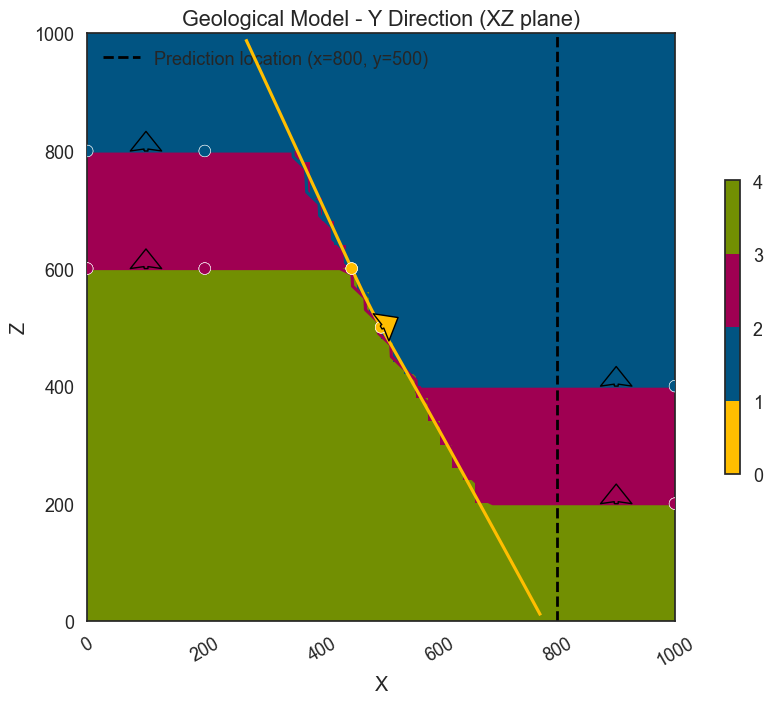

In [34]:
# Create plots with proper configuration
# Plot 1: Cross-section in Y direction (XZ plane)
p2d = gpv.plot_2d(
    model,
    cell_number=25,  # Middle of the model
    direction='y',
    show_data=True,
    show_boundaries=True,
    show_results=True,
    show=False
)
# Add vertical dashed line at prediction location (x=800, y=500)
p2d.axes[0].axvline(x=800, color='black', linestyle='--', linewidth=2, label='Prediction location (x=800, y=500)')
p2d.axes[0].legend()
p2d.axes[0].set_title("Geological Model - Y Direction (XZ plane)")
plt.tight_layout()
plt.show()

/Users/flow/opt/anaconda3/envs/gempy_sa/lib/python3.11/site-packages/gempy_viewer/API/_plot_2d_API.py:176: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  p.fig.show()


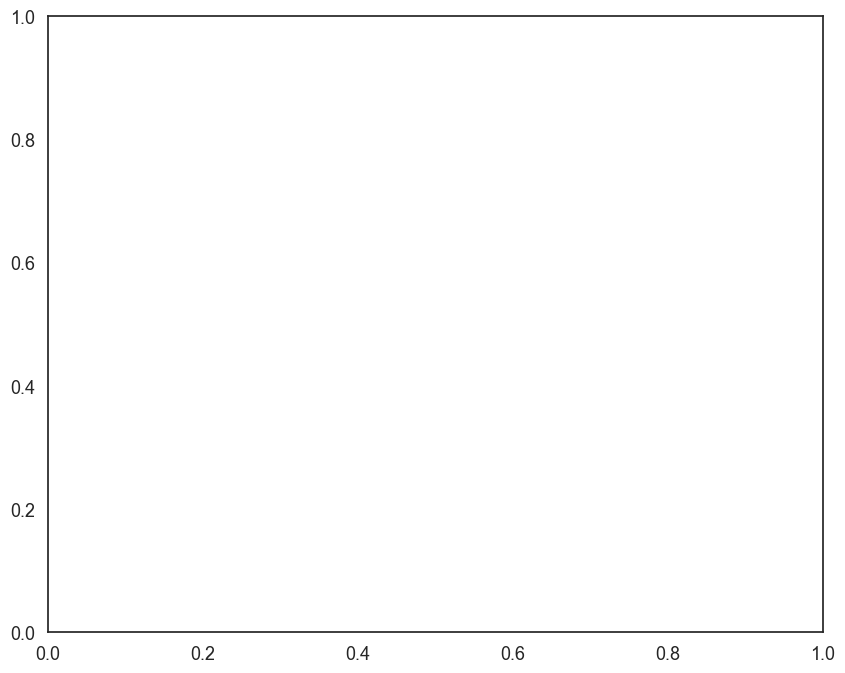

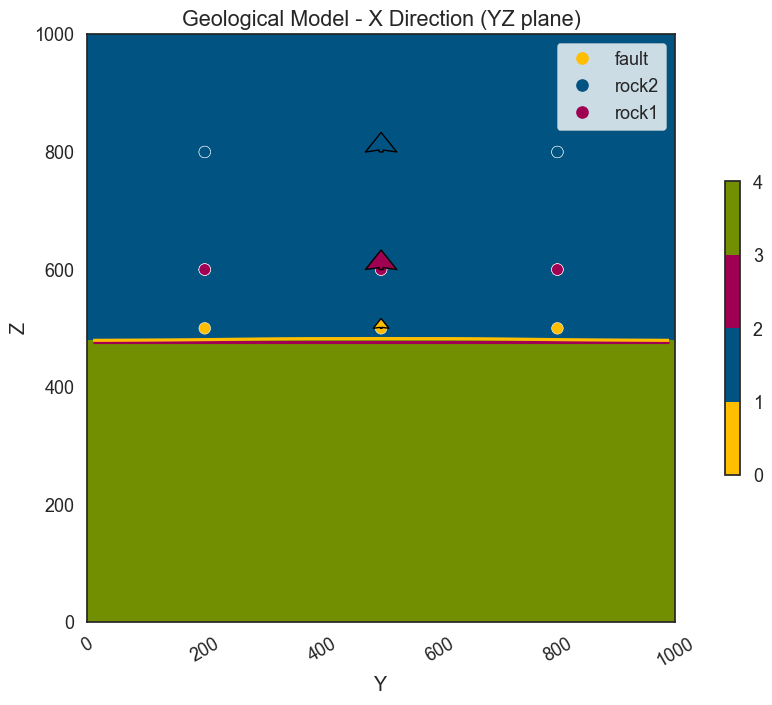

In [35]:
# Plot 2: Cross-section in X direction (YZ plane)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111)
gpv.plot_2d(
    model,
    cell_number=25,  # Middle of the model
    direction='x',
    show_data=True,
    show_boundaries=True,
    show_results=True,
    ax=ax
)
plt.title("Geological Model - X Direction (YZ plane)")
plt.tight_layout()
plt.show()

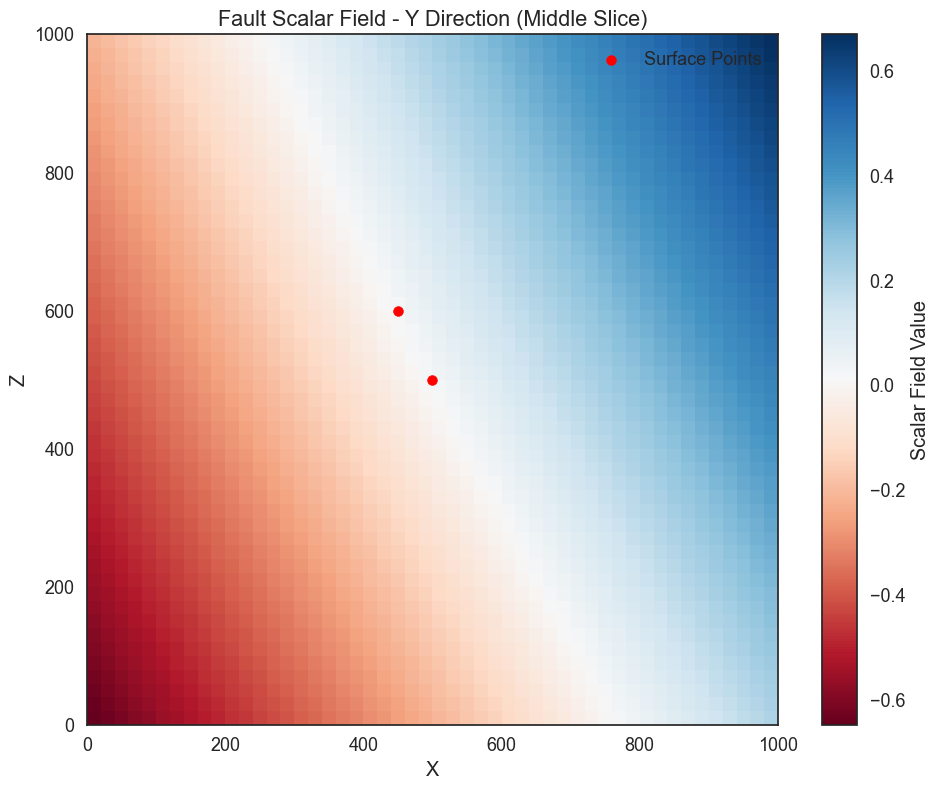

In [36]:
# Plot 3: Scalar field of the fault
plt.figure(figsize=(10, 8))
ax = plt.gca()

# Get scalar field values and reshape to grid
scalar_field = model.solutions.raw_arrays.scalar_field_matrix[0].reshape(50, 50, 50)

# Plot middle slice in Y direction
middle_slice = scalar_field[:, 25, :]
im = ax.imshow(middle_slice.T, 
               extent=[0, 1000, 0, 1000],
               origin='lower',
               cmap='RdBu',
               aspect='equal')

# Add colorbar
plt.colorbar(im, ax=ax, label='Scalar Field Value')

# Plot surface points
fault_element = model.structural_frame.get_element_by_name("fault")
if fault_element and fault_element.surface_points is not None:
    fault_points_coords = fault_element.surface_points.xyz

    # Filter points near the slice (Y around 500)
    mask = np.abs(fault_points_coords[:, 1] - 500) < 100
    filtered_points = fault_points_coords[mask]

    if len(filtered_points) > 0:
        ax.scatter(filtered_points[:, 0], filtered_points[:, 2], 
                  c='red', s=50, label='Surface Points')
        ax.legend()

ax.set_xlabel('X')
ax.set_ylabel('Z')
ax.set_title('Fault Scalar Field - Y Direction (Middle Slice)')
plt.tight_layout()
plt.show()

In [37]:
# Plot 4: 3D visualization (optional)
PLOT_3D = False  # Set to True to enable 3D plotting

if PLOT_3D:
    try:
        import pyvista as pv
        p = pv.Plotter(notebook=True)  # Use notebook=True for Jupyter
        gpv.plot_3d(
            model,
            show_data=True,
            show_surfaces=True,
            show_boundaries=True,
            plotter=p
        )
        p.show()
    except Exception as e:
        print(f"Could not create 3D plot: {e}")
else:
    print("3D plotting is disabled. Set PLOT_3D = True to enable.")

3D plotting is disabled. Set PLOT_3D = True to enable.


In [38]:
# Explore the scalar field structure and interface values
import numpy as np

print("=== Exploring Scalar Field Structure ===")
scalar_field_shape = model.solutions.raw_arrays.scalar_field_matrix.shape
print(f"Scalar field matrix shape: {scalar_field_shape}")
if len(scalar_field_shape) > 0 and scalar_field_shape[0] > 0:
    print(f"  - Number of series: {scalar_field_shape[0]}")
    if len(scalar_field_shape) > 1:
        print(f"  - Number of grid points: {scalar_field_shape[1]}")
    else:
        print(f"  - Note: Scalar field matrix is 1D")
else:
    print(f"  - WARNING: Scalar field matrix is empty!")
    print(f"  - This may happen if compute_model_at was called and changed the grid.")
    print(f"  - The model needs to be recomputed on the regular grid first.")

# Get rock1 and rock2 elements
rock1 = model.structural_frame.get_element_by_name("rock1")
rock2 = model.structural_frame.get_element_by_name("rock2")

print(f"\n=== Interface Values ===")
print(f"rock1.scalar_field_at_interface: {rock1.scalar_field_at_interface}")
print(f"rock2.scalar_field_at_interface: {rock2.scalar_field_at_interface}")

# Get the grid information
print(f"\n=== Grid Information ===")
if model.grid.regular_grid is not None:
    grid = model.grid.regular_grid
    print(f"Grid resolution: {grid.resolution}")
    print(f"Grid extent: {grid.extent}")
else:
    print(f"Regular grid is None (may have been reset by compute_model_at)")
    print(f"Grid extent (from model.grid.extent): {model.grid.extent}")

# Check which series contains rock1 and rock2 (likely Strat_Series)
print(f"\n=== Series Information ===")
for i, group in enumerate(model.structural_frame.structural_groups):
    print(f"Series {i}: {group.name}, Elements: {[e.name for e in group.elements]}")
    
# The scalar field matrix has shape (n_series, n_grid_points)
# For Strat_Series (index 1), we need to find where the scalar field equals 
# the interface value of rock1 to locate the interface between rock1 and rock2
print(f"\n=== Finding Interface ===")
print(f"The interface between rock1 and rock2 occurs where the scalar field equals {rock1.scalar_field_at_interface}")
print(f"This is stored in rock1.scalar_field_at_interface after model computation.")

=== Exploring Scalar Field Structure ===
Scalar field matrix shape: (2, 125000)
  - Number of series: 2
  - Number of grid points: 125000

=== Interface Values ===
rock1.scalar_field_at_interface: -0.2999999791771859
rock2.scalar_field_at_interface: -0.09999998177953257

=== Grid Information ===
Grid resolution: [50 50 50]
Grid extent: [   0. 1000.    0. 1000.    0. 1000.]

=== Series Information ===
Series 0: Fault_Series, Elements: [np.str_('fault')]
Series 1: Strat_Series, Elements: [np.str_('rock2'), np.str_('rock1')]

=== Finding Interface ===
The interface between rock1 and rock2 occurs where the scalar field equals -0.2999999791771859
This is stored in rock1.scalar_field_at_interface after model computation.


In [39]:
# Find interface depth at prediction location (x=800, y=500) using PyTorch-compatible approach
# We'll use compute_model_at to evaluate the scalar field at specific coordinates along the z-axis

# IMPORTANT: Ensure model is computed on regular grid first
# If compute_model_at was run before, the regular grid may be reset
# Check if we need to reload/recompute the model BEFORE calling compute_model_at
# Note: We need the regular grid computation to get interface values (scalar_field_at_interface)
needs_reload = False
if model.solutions is None:
    needs_reload = True
elif model.grid.regular_grid is None:
    needs_reload = True
elif not hasattr(model.solutions, 'raw_arrays') or model.solutions.raw_arrays.scalar_field_matrix.size == 0:
    # Check if regular grid computation exists (scalar_field_matrix should be populated for regular grids)
    needs_reload = True

if needs_reload:
    print("Model not computed on regular grid. Reloading from JSON...")
    json_path = "/Users/flow/git/gempy/examples/tutorials/z_other_tutorials/json_io/multiple_series_faults.json"
    model = JsonIO.load_model_from_json(json_path)
    # Recompute on regular grid with PyTorch backend
    engine_config = GemPyEngineConfig(
        backend=AvailableBackends.PYTORCH,
        use_gpu=False,
        dtype='float64'
    )
    gp.compute_model(model, engine_config=engine_config)
    print("Model reloaded and recomputed on regular grid.")
    print(f"Note: There are 2 geological interfaces (rock1-rock2) in Strat_Series, plus 1 fault.")
    print(f"We only need the scalar field from Strat_Series (index 1) for interface prediction.")

pred_x = 800.0
pred_y = 500.0

# Get the z-range from the grid extent
# Use model.grid.extent which works with dense_grid or octree_grid
# We need to get this BEFORE calling compute_model_at, as it may reset the grid
z_min, z_max = model.grid.extent[4], model.grid.extent[5]

# ============================================================================
# NOTE ON CUSTOM GRID ARCHITECTURE IN GEMPY V3:
# ============================================================================
# The current implementation of compute_model_at() goes through the full
# computation pipeline including octrees and dual contouring, which doesn't
# make architectural sense for custom grids. For custom grids, we should be
# able to directly evaluate scalar fields at specific points using the
# already-computed interpolation weights, without octrees.
#
# However, we work with the current API: compute_model_at() sets a custom grid
# and calls compute_model(), which goes through octrees. We then extract
# scalar field values from the octree structure (root_output.outputs_centers).
# ============================================================================

# Sample along z-axis at x=800, y=500 with fine resolution
# We'll use a binary search approach to find where scalar field equals interface value
n_samples = 200
z_samples = np.linspace(z_min, z_max, n_samples)

# Create coordinate array for compute_model_at: shape (n_samples, 3)
coords = np.column_stack([
    np.full(n_samples, pred_x),
    np.full(n_samples, pred_y),
    z_samples
])

print(f"Computing scalar field at {n_samples} points along z-axis at x={pred_x}, y={pred_y}...")
print(f"Z-range: {z_min} to {z_max}")

# IMPORTANT: Disable octrees for custom grid computation
# Octrees are used for adaptive refinement on regular grids, but for custom grids
# we want direct evaluation without octree overhead
original_octree_levels = model.interpolation_options.number_octree_levels
model.interpolation_options.number_octree_levels = 1  # Set to 1 level
print(f"Set octree levels (was {original_octree_levels}, now 1) for custom grid computation")

# Use compute_model_at with PyTorch backend to evaluate scalar field at these coordinates
# This will use the same PyTorch backend that was used for the main model computation
# Use compute_model_at with PyTorch backend - it updates model.solutions with scalar field values
tmp = gp.compute_model_at(
    gempy_model=model,
    at=coords,
    engine_config=engine_config  # Use the same PyTorch engine_config
)

# Restore original octree levels
model.interpolation_options.number_octree_levels = original_octree_levels
print(f"Restored octree levels to {original_octree_levels}")

# After compute_model_at, access scalar field values from octree structure
# For custom grids with octree_levels=1, scalar fields are stored in root_output.outputs_centers

print("\n=== Checking custom grid coordinates ===")
# Check what coordinates were actually used
if hasattr(model.grid, 'custom_grid') and model.grid.custom_grid is not None:
    custom_coords = model.grid.custom_grid.values
    if hasattr(custom_coords, 'detach'):
        custom_coords_np = custom_coords.detach().cpu().numpy()
    elif hasattr(custom_coords, 'numpy'):
        custom_coords_np = custom_coords.numpy()
    else:
        custom_coords_np = np.asarray(custom_coords)
    print(f"  Custom grid shape: {custom_coords_np.shape}")
    print(f"  Custom grid z-range: [{custom_coords_np[:, 2].min():.2f}, {custom_coords_np[:, 2].max():.2f}]")
    print(f"  Custom grid first 3 points:\n{custom_coords_np[:3]}")
    print(f"  Custom grid last 3 points:\n{custom_coords_np[-3:]}")

print("\n=== Extracting scalar field from octree structure ===")
sol = model.solutions

# Get Strat_Series scalar field from root_output
# Based on investigation: outputs_centers[1] corresponds to Strat_Series (index 1)
if not hasattr(sol, 'root_output'):
    raise ValueError("root_output not found in solutions")

root = sol.root_output
if not hasattr(root, 'outputs_centers'):
    raise ValueError("outputs_centers not found in root_output")

if len(root.outputs_centers) < 2:
    raise ValueError(f"Expected at least 2 outputs_centers, got {len(root.outputs_centers)}")

# Strat_Series is index 1, so outputs_centers[1] should contain its scalar field
strat_output_center = root.outputs_centers[1]

if not hasattr(strat_output_center, 'scalar_fields'):
    raise ValueError("scalar_fields not found in Strat_Series output_center")

sf = strat_output_center.scalar_fields
if not hasattr(sf, 'exported_fields'):
    raise ValueError("exported_fields not found in scalar_fields")

ef = sf.exported_fields
if not hasattr(ef, 'scalar_field'):
    raise ValueError("scalar_field not found in exported_fields")

# Extract scalar field tensor and convert to numpy
strat_scalar_field_tensor = ef.scalar_field
print(f"✓ Found Strat_Series scalar field!")
print(f"  Tensor shape: {strat_scalar_field_tensor.shape}")
print(f"  Tensor type: {type(strat_scalar_field_tensor)}")

# Convert torch tensor to numpy array
if hasattr(strat_scalar_field_tensor, 'detach'):
    strat_scalar_field = strat_scalar_field_tensor.detach().cpu().numpy()
elif hasattr(strat_scalar_field_tensor, 'numpy'):
    strat_scalar_field = strat_scalar_field_tensor.numpy()
else:
    strat_scalar_field = np.asarray(strat_scalar_field_tensor)

# Ensure it's 1D and matches our number of samples
strat_scalar_field = strat_scalar_field.flatten()

print(f"  Numpy array shape: {strat_scalar_field.shape}")
print(f"  Number of samples: {n_samples}")

# The scalar field might contain values for all series stacked
# If shape doesn't match n_samples, we need to extract the right portion
if strat_scalar_field.shape[0] != n_samples:
    # If it's larger, it might contain values for multiple series
    # For Strat_Series (index 1), we might need to take every nth value or a slice
    # Let's check: if shape is n_samples * n_series, we need series index 1
    n_series = len(root.outputs_centers)
    if strat_scalar_field.shape[0] == n_samples * n_series:
        # Extract Strat_Series values (every nth value starting from index 1)
        strat_scalar_field = strat_scalar_field[1::n_series]
        print(f"  Extracted Strat_Series values (shape after extraction: {strat_scalar_field.shape})")
    elif strat_scalar_field.shape[0] > n_samples:
        # Take first n_samples values (might be wrong, but let's try)
        strat_scalar_field = strat_scalar_field[:n_samples]
        print(f"  Taking first {n_samples} values (shape: {strat_scalar_field.shape})")
    else:
        raise ValueError(
            f"Scalar field shape {strat_scalar_field.shape[0]} doesn't match "
            f"number of samples {n_samples} and can't be interpreted"
        )

print(f"\nStrat_Series scalar field shape: {strat_scalar_field.shape}")
print(f"Strat_Series scalar field min: {strat_scalar_field.min():.4f}, max: {strat_scalar_field.max():.4f}")

# IMPORTANT: Use the actual custom grid coordinates for mapping
# The scalar field values correspond to the coordinates stored in model.grid.custom_grid.values
# These are the coordinates we passed in (before transformation), so they match our z_samples
if hasattr(model.grid, 'custom_grid') and model.grid.custom_grid is not None:
    # Get z-coordinates from the custom grid (these are our original coordinates)
    custom_z_coords = custom_coords_np[:, 2]  # z-coordinates
    print(f"\n  Custom grid z-coordinates shape: {custom_z_coords.shape}")
    print(f"  Custom grid z-range: [{custom_z_coords.min():.2f}, {custom_z_coords.max():.2f}]")
    
    # Ensure scalar field and z-coordinates have the same length
    if len(strat_scalar_field) != len(custom_z_coords):
        min_len = min(len(strat_scalar_field), len(custom_z_coords))
        strat_scalar_field = strat_scalar_field[:min_len]
        custom_z_coords = custom_z_coords[:min_len]
        print(f"  Trimmed to match length: {min_len}")
    
    # Sort by z-coordinate to ensure proper ordering for interpolation
    # (in case coordinates got reordered during computation)
    sort_idx = np.argsort(custom_z_coords)
    custom_z_coords_sorted = custom_z_coords[sort_idx]
    strat_scalar_field_sorted = strat_scalar_field[sort_idx]
    
    print(f"  After sorting: z-range [{custom_z_coords_sorted.min():.2f}, {custom_z_coords_sorted.max():.2f}]")
else:
    # Fallback: use original z_samples
    custom_z_coords_sorted = z_samples
    strat_scalar_field_sorted = strat_scalar_field
    print(f"  Warning: Using original z_samples (custom grid not found)")

# Get interface value
interface_value = rock1.scalar_field_at_interface
print(f"Looking for interface value: {interface_value:.4f}")

# Find where scalar field crosses the interface value
# The interface is where scalar_field == rock1.scalar_field_at_interface
diff = strat_scalar_field_sorted - interface_value

# Ensure diff is a 1D array (flatten if needed)
diff = np.asarray(diff).flatten()

# Find sign changes indicating crossing of the interface
sign_changes = np.where(np.diff(np.sign(diff)))[0]

if len(sign_changes) > 0:
    # Interpolate to find exact z-value at the interface
    idx = sign_changes[0]
    z1, z2 = custom_z_coords_sorted[idx], custom_z_coords_sorted[idx + 1]
    val1, val2 = strat_scalar_field_sorted[idx], strat_scalar_field_sorted[idx + 1]
    
    # Debug: print coordinate information
    print(f"\n=== Debugging coordinate mapping ===")
    print(f"  z_samples range: [{z_samples.min():.2f}, {z_samples.max():.2f}]")
    print(f"  z_samples[0]: {z_samples[0]:.2f}, z_samples[-1]: {z_samples[-1]:.2f}")
    print(f"  Crossing found at index: {idx}")
    print(f"  z1: {z1:.2f}, z2: {z2:.2f}")
    print(f"  val1: {val1:.4f}, val2: {val2:.4f}")
    print(f"  interface_value: {interface_value:.4f}")
    
    # Check if coordinates might be scaled
    # The model extent should give us the original coordinate system
    model_extent = model.grid.extent
    print(f"\n  Model extent: {model_extent}")
    print(f"  Model extent z-range: [{model_extent[4]:.2f}, {model_extent[5]:.2f}]")
    
    # Linear interpolation to find exact z where scalar field equals interface value
    pred_z = z1 + (interface_value - val1) * (z2 - z1) / (val2 - val1)
    
    print(f"\n✓ Found interface crossing!")
    print(f"  Predicted interface depth at x={pred_x}, y={pred_y}: z={pred_z:.2f}")
    print(f"  Scalar field value at interface: {interface_value:.4f}")
else:
    print(f"\n✗ Could not find interface crossing at this location")
    print(f"  Scalar field range: [{strat_scalar_field.min():.4f}, {strat_scalar_field.max():.4f}]")
    print(f"  Interface value: {interface_value:.4f}")

Computing scalar field at 200 points along z-axis at x=800.0, y=500.0...
Z-range: 0.0 to 1000.0
Set octree levels (was 4, now 1) for custom grid computation
Active grids: GridTypes.CUSTOM|NONE
Setting Backend To: AvailableBackends.PYTORCH
Using sequential processing for 3 surfaces
Restored octree levels to 4

=== Checking custom grid coordinates ===
  Custom grid shape: (200, 3)
  Custom grid z-range: [0.00, 1000.00]
  Custom grid first 3 points:
[[800.         500.           0.        ]
 [800.         500.           5.02512563]
 [800.         500.          10.05025126]]
  Custom grid last 3 points:
[[ 800.          500.          989.94974874]
 [ 800.          500.          994.97487437]
 [ 800.          500.         1000.        ]]

=== Extracting scalar field from octree structure ===
✓ Found Strat_Series scalar field!
  Tensor shape: torch.Size([272])
  Tensor type: <class 'torch.Tensor'>
  Numpy array shape: (272,)
  Number of samples: 200
  Taking first 200 values (shape: (200,))


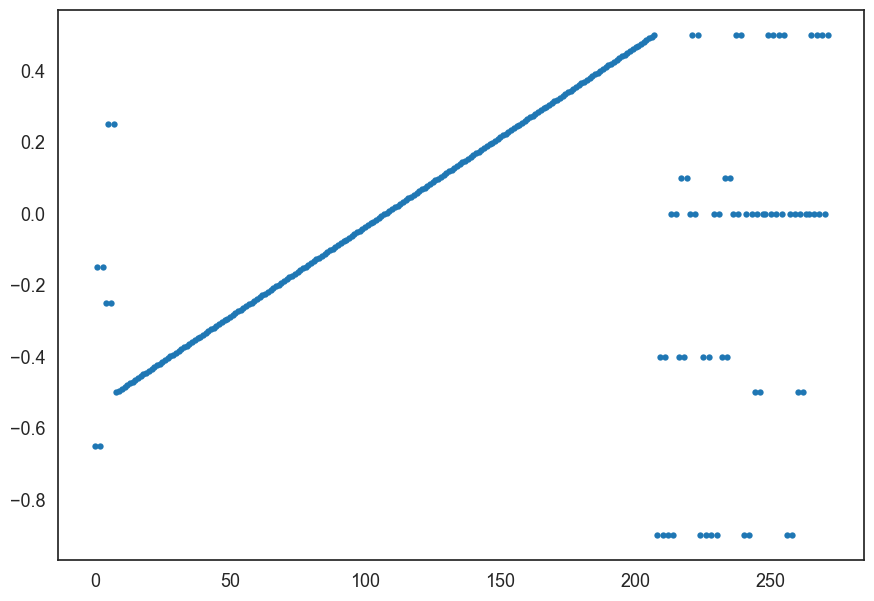

In [40]:
plt.plot(sol.root_output.outputs_centers[1].scalar_fields.exported_fields.scalar_field, '.')

# Architecture Analysis: `compute_model_at()` and Custom Grids

## Current Implementation Flow (Step-by-Step)

### Level 1: `compute_model_at()` (gempy/API/compute_API.py:68-92)
```python
def compute_model_at(gempy_model: GeoModel, at: np.ndarray, ...):
    # Step 1: Set custom grid (modifies gempy_model.grid)
    set_custom_grid(grid=gempy_model.grid, xyz_coord=at, reset=True)
    
    # Step 2: Call regular compute_model() function
    sol = compute_model(gempy_model, engine_config, ...)
    
    # Step 3: Return only lithology (not scalar field!)
    return sol.raw_arrays.custom  # ⚠️ This is lithology, not scalar field!
```

### Level 2: `compute_model()` (gempy/API/compute_API.py:20-65)
```python
def compute_model(gempy_model: GeoModel, ...):
    # Step 1: Build interpolation input from structural frame
    interpolation_input = interpolation_input_from_structural_frame(gempy_model)
    #   - Extracts: surface_points, orientations, grid (including custom_grid)
    #   - Reuses weights from previous computation if available
    
    # Step 2: Call gempy_engine.compute_model() (EXTERNAL PACKAGE)
    gempy_model.solutions = gempy_engine.compute_model(
        interpolation_input=interpolation_input,
        options=gempy_model.interpolation_options,  # ⚠️ Includes octree settings!
        data_descriptor=gempy_model.input_data_descriptor,
        geophysics_input=gempy_model.geophysics_input,
    )
```

### Level 3: `interpolation_input_from_structural_frame()` (gempy/modules/data_manipulation/_engine_factory.py:14-58)
```python
def interpolation_input_from_structural_frame(geo_model):
    # Step 1: Extract surface points and orientations (transformed)
    surface_points = SurfacePoints(...)
    orientations = Orientations(...)
    
    # Step 2: Convert grid to engine_grid format
    grid = _apply_input_transform_to_grids(grid, input_transform, ...)
    #   - If custom_grid exists: creates engine_grid.GenericGrid(values=transformed_coords)
    #   - ALWAYS creates octree_grid (even for custom grids!) - Line 93-96
    
    # Step 3: Reuse weights from previous computation (if available)
    weights = []
    if geo_model.solutions is not None:
        for stack_sol in geo_model.solutions.root_output.outputs_centers:
            weights.append(stack_sol.weights)
    
    # Step 4: Create InterpolationInput
    return InterpolationInput(
        surface_points=surface_points,
        orientations=orientations,
        grid=grid,  # Contains custom_grid AND octree_grid
        unit_values=structural_frame.elements_ids,
        weights=weights  # May be empty for first computation
    )
```

### Level 4: `gempy_engine.compute_model()` (EXTERNAL - gempy_engine package)
**This is where the problem occurs:**
- Receives `InterpolationInput` with custom_grid AND octree_grid
- Receives `interpolation_options` with `number_octree_levels` setting
- **Always goes through octree pipeline**, even when only custom_grid is needed
- Returns `Solutions` with scalar fields stored in octree structure

## The Architectural Problem

### Why Octrees Don't Make Sense for Custom Grids

1. **Octrees are for adaptive refinement**: They subdivide regular grids where interfaces are complex
2. **Custom grids are arbitrary points**: They have no spatial ordering or structure
3. **Dual contouring extracts meshes**: We don't need meshes, just scalar field values
4. **Unnecessary overhead**: Computing octrees for custom grids wastes computation

### The Bug in `_apply_input_transform_to_grids()` (Line 93-96)

```python
# This ALWAYS creates an octree_grid, even when only custom_grid is needed!
octree_grid = engine_grid.RegularGrid(
    orthogonal_extent=new_extents,
    regular_grid_shape=base_grid_resolution  # Default: [2, 2, 2]
)
grid: engine_grid.EngineGrid = engine_grid.EngineGrid(
    octree_grid=octree_grid,  # ⚠️ BUG: Always created!
    custom_grid=custom_values,  # Our custom points
    ...
)
```

**Comment in code (line 98)**: `# BUG: Adapt the engine to deal with this`

## What Should Happen

### Ideal Flow for Custom Grids

```
compute_model_at(gempy_model, at=coords)
  ↓
set_custom_grid(grid, xyz_coord=at)
  ↓
interpolation_input_from_structural_frame(gempy_model)
  ↓ (creates InterpolationInput with ONLY custom_grid, NO octree_grid)
  ↓
gempy_engine.evaluate_scalar_field_direct(interpolation_input, ...)
  ↓ (Direct evaluation using interpolation function - NO octrees)
  ↓
Returns scalar field values directly
```

### Required Changes

1. **In `gempy/modules/data_manipulation/_engine_factory.py`**:
   - Don't create `octree_grid` when only `custom_grid` is active
   - Or set `octree_grid=None` when only custom evaluation is needed

2. **In `gempy_engine` package** (external, needs modification):
   - Add `evaluate_scalar_field_direct()` function that:
     - Takes `InterpolationInput` with custom_grid
     - Uses interpolation function directly (kriging/cokriging)
     - Skips octree pipeline entirely
     - Returns scalar field values
   - Or modify `compute_model()` to detect custom-only grids and skip octrees

3. **In `gempy/API/compute_API.py`**:
   - Modify `compute_model_at()` to:
     - Return scalar field values, not just lithology
     - Use direct evaluation path when possible

## Where Scalar Field Values Are Stored

**Critical Finding**: Scalar field values ARE calculated (they must be, since lithology is derived from them), but they're stored in an unexpected location:

### After `compute_model_at()`:

1. **`sol.raw_arrays.custom`** = **Lithology only** (integers mapping to rock types)
   - This is what `compute_model_at()` returns
   - Shape: `(n_points,)` - one integer per custom grid point

2. **`sol.raw_arrays.scalar_field_matrix`** = **EMPTY for custom grids**
   - This is populated for regular grids, but NOT for custom grids
   - Shape: `(0,)` or empty

3. **`sol.root_output.outputs_centers[series_index].scalar_fields.exported_fields.scalar_field`** = **✓ SCALAR FIELD VALUES HERE!**
   - This is where the actual scalar field values are stored
   - Shape: `(n_points,)` or `(n_series * n_points,)` depending on how values are stacked
   - Values are stored as PyTorch tensors (need `.detach().cpu().numpy()` to convert)

### Why This Is Confusing:

- `compute_model_at()` returns lithology, not scalar fields
- Scalar fields are stored in the octree structure (`root_output`), not in `raw_arrays`
- This forces users to navigate the octree structure even for simple custom grid evaluation

## Current Workaround

Since we can't modify `gempy_engine` directly:
1. Set `number_octree_levels=1` to minimize octree overhead
2. Extract scalar field from `root_output.outputs_centers[series_index].scalar_fields.exported_fields.scalar_field`
3. Handle potential stacking: values may be interleaved by series (e.g., `[series0_pt0, series1_pt0, series0_pt1, series1_pt1, ...]`)
4. Map values back to original coordinates (accounting for transformations)

## References

- **`gempy/API/compute_API.py`**: Lines 68-92 (`compute_model_at()`), Lines 20-65 (`compute_model()`)
- **`gempy/modules/data_manipulation/_engine_factory.py`**: Lines 14-58 (`interpolation_input_from_structural_frame()`), Lines 61-105 (`_apply_input_transform_to_grids()`)
- **`gempy_engine.compute_model()`**: External package function (needs modification or new function)

In [42]:
# ============================================================================
# INVESTIGATION: Where are scalar field values stored after compute_model_at()?
# ============================================================================
# The user correctly points out: lithology is derived from scalar field values,
# so scalar fields MUST be calculated and stored somewhere!
# Let's trace through the Solutions object structure to find them.

import numpy as np
import gempy as gp
from gempy.core.data.gempy_engine_config import GemPyEngineConfig
from gempy_engine.config import AvailableBackends
from gempy.modules.json_io.json_operations import JsonIO

print("=" * 80)
print("INVESTIGATION: Scalar Field Storage After compute_model_at()")
print("=" * 80)

# Reload model and compute on regular grid first
json_path = "/Users/flow/git/gempy/examples/tutorials/z_other_tutorials/json_io/multiple_series_faults.json"
model = JsonIO.load_model_from_json(json_path)
engine_config = GemPyEngineConfig(
    backend=AvailableBackends.PYTORCH,
    use_gpu=False,
    dtype='float64'
)
gp.compute_model(model, engine_config=engine_config)
print("\n✓ Model computed on regular grid")

# Create a simple custom grid with 3 points
test_coords = np.array([
    [500, 500, 200],
    [500, 500, 500], 
    [500, 500, 800]
])

print(f"\n--- Testing with custom grid: {len(test_coords)} points ---")
print(f"Coordinates:\n{test_coords}")

# Set octree levels to 1 (minimal)
original_octree_levels = model.interpolation_options.number_octree_levels
model.interpolation_options.number_octree_levels = 1

# Call compute_model_at
print("\n--- Calling compute_model_at() ---")
lithology = gp.compute_model_at(model, test_coords, engine_config=engine_config)
print(f"Returned lithology shape: {lithology.shape}")
print(f"Returned lithology values: {lithology}")

# Restore octree levels
model.interpolation_options.number_octree_levels = original_octree_levels

# Now investigate the Solutions object structure
sol = model.solutions
print("\n" + "=" * 80)
print("SOLUTIONS OBJECT STRUCTURE")
print("=" * 80)

print(f"\n1. sol type: {type(sol)}")
print(f"   sol.raw_arrays type: {type(sol.raw_arrays)}")
print(f"   sol.raw_arrays.custom shape: {sol.raw_arrays.custom.shape if hasattr(sol.raw_arrays, 'custom') else 'N/A'}")
print(f"   sol.raw_arrays.custom values: {sol.raw_arrays.custom if hasattr(sol.raw_arrays, 'custom') else 'N/A'}")

# Check if scalar_field_matrix exists for custom grids
if hasattr(sol.raw_arrays, 'scalar_field_matrix'):
    print(f"\n2. sol.raw_arrays.scalar_field_matrix shape: {sol.raw_arrays.scalar_field_matrix.shape}")
    print(f"   scalar_field_matrix size: {sol.raw_arrays.scalar_field_matrix.size}")
    if sol.raw_arrays.scalar_field_matrix.size > 0:
        print(f"   scalar_field_matrix values (first few): {sol.raw_arrays.scalar_field_matrix[:, :3] if sol.raw_arrays.scalar_field_matrix.ndim == 2 else 'N/A'}")
    else:
        print("   ⚠️ scalar_field_matrix is EMPTY for custom grids!")

# Check root_output structure
print(f"\n3. sol.root_output type: {type(sol.root_output)}")
if hasattr(sol.root_output, 'outputs_centers'):
    print(f"   sol.root_output.outputs_centers length: {len(sol.root_output.outputs_centers)}")
    
    for i, output_center in enumerate(sol.root_output.outputs_centers):
        print(f"\n   Output center {i}:")
        print(f"     Type: {type(output_center)}")
        
        if hasattr(output_center, 'scalar_fields'):
            sf = output_center.scalar_fields
            print(f"     Has scalar_fields: True")
            
            if hasattr(sf, 'exported_fields'):
                ef = sf.exported_fields
                print(f"       Has exported_fields: True")
                
                if hasattr(ef, 'scalar_field'):
                    scalar_field = ef.scalar_field
                    # Handle both property and method
                    if hasattr(scalar_field, 'detach'):
                        scalar_field_np = scalar_field.detach().cpu().numpy()
                    elif hasattr(scalar_field, 'numpy'):
                        scalar_field_np = scalar_field.numpy()
                    else:
                        scalar_field_np = np.asarray(scalar_field)
                    
                    print(f"       scalar_field shape: {scalar_field_np.shape}")
                    print(f"       scalar_field values: {scalar_field_np}")
                    print(f"       ✓ FOUND SCALAR FIELD VALUES HERE!")
                else:
                    print(f"       ⚠️ exported_fields.scalar_field not found")
                    print(f"       exported_fields attributes: {[x for x in dir(ef) if not x.startswith('_')]}")
            else:
                print(f"     ⚠️ scalar_fields.exported_fields not found")
                print(f"     scalar_fields attributes: {[x for x in dir(sf) if not x.startswith('_')]}")
        else:
            print(f"     ⚠️ scalar_fields not found")
            print(f"     output_center attributes: {[x for x in dir(output_center) if not x.startswith('_')]}")

# Check octrees_output
if hasattr(sol, 'octrees_output') and sol.octrees_output is not None:
    print(f"\n4. sol.octrees_output length: {len(sol.octrees_output)}")
    if len(sol.octrees_output) > 0:
        octree_output = sol.octrees_output[0]
        print(f"   octrees_output[0] type: {type(octree_output)}")
        if hasattr(octree_output, 'outputs_centers'):
            print(f"   octrees_output[0].outputs_centers length: {len(octree_output.outputs_centers)}")

print("\n" + "=" * 80)
print("CONCLUSION")
print("=" * 80)
print("""
After compute_model_at():
1. sol.raw_arrays.custom = lithology (derived from scalar fields)
2. sol.raw_arrays.scalar_field_matrix = EMPTY for custom grids
3. sol.root_output.outputs_centers[i].scalar_fields.exported_fields.scalar_field = 
   ✓ THIS IS WHERE THE SCALAR FIELD VALUES ARE STORED!

The scalar fields ARE calculated (they must be, to derive lithology), but they're
stored in the octree structure (root_output.outputs_centers), not in raw_arrays.
This is the architectural issue: custom grids go through octree pipeline even
though they don't need it.
""")

INVESTIGATION: Scalar Field Storage After compute_model_at()
Setting Backend To: AvailableBackends.PYTORCH
Chunking done: 8 chunks
Using sequential processing for 3 surfaces

✓ Model computed on regular grid

--- Testing with custom grid: 3 points ---
Coordinates:
[[500 500 200]
 [500 500 500]
 [500 500 800]]

--- Calling compute_model_at() ---
Active grids: GridTypes.CUSTOM|NONE
Setting Backend To: AvailableBackends.PYTORCH
Using sequential processing for 3 surfaces
Returned lithology shape: (3,)
Returned lithology values: [4. 3. 2.]

SOLUTIONS OBJECT STRUCTURE

1. sol type: <class 'gempy_engine.core.data.solutions.Solutions'>
   sol.raw_arrays type: <class 'gempy_engine.core.data.raw_arrays_solution.RawArraysSolution'>
   sol.raw_arrays.custom shape: (3,)
   sol.raw_arrays.custom values: [4. 3. 2.]

2. sol.raw_arrays.scalar_field_matrix shape: (0,)
   scalar_field_matrix size: 0
   ⚠️ scalar_field_matrix is EMPTY for custom grids!

3. sol.root_output type: <class 'gempy_engine.core.d

COMPARISON: Regular Grid vs Custom Grid Scalar Field Values
Setting Backend To: AvailableBackends.PYTORCH
Chunking done: 8 chunks
Using sequential processing for 3 surfaces
✓ Model computed on regular grid

--- Comparison Location ---
x = 800.0, y = 500.0
z-range: [0.0, 1000.0]
Number of samples: 200

--- Extracting from Regular Grid ---
Available in raw_arrays:
  scalar_field_matrix: True
  lith_block: True
  block_matrix: True

Regular grid scalar_field_matrix shape: (2, 125000)
  - Series: 2
  - Grid points: 125000

Checking data type:
  dtype: float64
  Sample values (first 10): [-0.88999792 -0.86999793 -0.84999793 -0.82999793 -0.80999793 -0.78999793
 -0.76999794 -0.74999794 -0.72999794 -0.70999794]
  Min: -0.8900, Max: 0.4900
  Are values integers? False

Strat_Series scalar field shape: (125000,)
✓ scalar_field_matrix contains scalar field values (floats)

Regular grid resolution: [50 50 50]
Regular grid extent: [   0. 1000.    0. 1000.    0. 1000.]

Grid indices: x_idx=40, y_idx

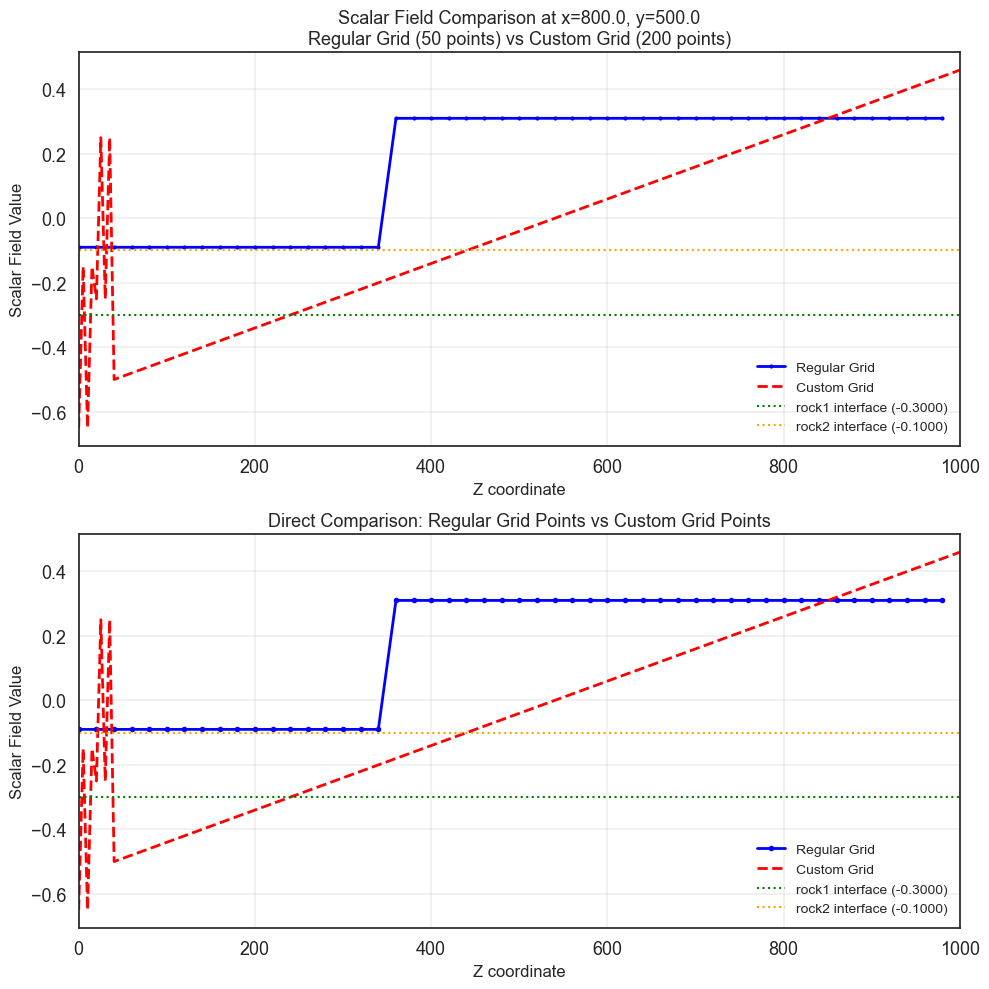


COMPARISON SUMMARY
Regular grid points: 50
Custom grid points: 200

Regular grid:
  Z-coords range: [0.00, 980.00]
  SF values range: [-0.0900, 0.3100]

Custom grid:
  Z-coords range: [0.00, 1000.00]
  SF values range: [-0.6500, 0.4598]

Note: Compare the curves visually in the plots above.
      If custom grid values appear random/scattered, check:
      1. Coordinate transformation issues
      2. Ordering/stacking issues in custom grid values
      3. Octree level affecting precision


In [45]:
# ============================================================================
# COMPARISON: Regular Grid vs Custom Grid Scalar Field Values
# ============================================================================
# Compare scalar field values from regular grid and custom grid at the same location
# to understand why custom grid values might not make sense

import numpy as np
import matplotlib.pyplot as plt
import gempy as gp
from gempy.core.data.gempy_engine_config import GemPyEngineConfig
from gempy_engine.config import AvailableBackends
from gempy.modules.json_io.json_operations import JsonIO

print("=" * 80)
print("COMPARISON: Regular Grid vs Custom Grid Scalar Field Values")
print("=" * 80)

# Reload model and compute on regular grid
json_path = "/Users/flow/git/gempy/examples/tutorials/z_other_tutorials/json_io/multiple_series_faults.json"
model = JsonIO.load_model_from_json(json_path)
engine_config = GemPyEngineConfig(
    backend=AvailableBackends.PYTORCH,
    use_gpu=False,
    dtype='float64'
)
gp.compute_model(model, engine_config=engine_config)
print("✓ Model computed on regular grid")

# Choose location for comparison (same as prediction location)
pred_x = 800.0
pred_y = 500.0
z_min, z_max = model.grid.extent[4], model.grid.extent[5]
n_samples = 200  # Same resolution as before
z_samples = np.linspace(z_min, z_max, n_samples)

print(f"\n--- Comparison Location ---")
print(f"x = {pred_x}, y = {pred_y}")
print(f"z-range: [{z_min}, {z_max}]")
print(f"Number of samples: {n_samples}")

# ============================================================================
# 1. Extract scalar field from REGULAR GRID
# ============================================================================
print("\n--- Extracting from Regular Grid ---")

# Check what's available in raw_arrays
print("Available in raw_arrays:")
print(f"  scalar_field_matrix: {hasattr(model.solutions.raw_arrays, 'scalar_field_matrix')}")
print(f"  lith_block: {hasattr(model.solutions.raw_arrays, 'lith_block')}")
print(f"  block_matrix: {hasattr(model.solutions.raw_arrays, 'block_matrix')}")

# Get regular grid scalar field matrix
regular_sf_matrix = model.solutions.raw_arrays.scalar_field_matrix
print(f"\nRegular grid scalar_field_matrix shape: {regular_sf_matrix.shape}")
print(f"  - Series: {regular_sf_matrix.shape[0]}")
print(f"  - Grid points: {regular_sf_matrix.shape[1]}")

# Check if these are actually scalar fields (floats) or lithology (integers)
print(f"\nChecking data type:")
print(f"  dtype: {regular_sf_matrix.dtype}")
print(f"  Sample values (first 10): {regular_sf_matrix[1, :10]}")
print(f"  Min: {regular_sf_matrix[1].min():.4f}, Max: {regular_sf_matrix[1].max():.4f}")
print(f"  Are values integers? {np.allclose(regular_sf_matrix[1], regular_sf_matrix[1].astype(int))}")

# Get Strat_Series scalar field (index 1)
strat_sf_regular = regular_sf_matrix[1]  # Strat_Series
print(f"\nStrat_Series scalar field shape: {strat_sf_regular.shape}")

# If these are lithology values, we need to find the actual scalar field
# For regular grids, scalar fields might be in block_matrix or we need to extract from octree structure
if np.allclose(strat_sf_regular, strat_sf_regular.astype(int)):
    print("\n⚠️ WARNING: scalar_field_matrix appears to contain lithology (integers), not scalar fields!")
    print("   Need to extract scalar field from octree structure for regular grid too.")
    
    # Extract from octree structure for regular grid
    if hasattr(model.solutions, 'octrees_output') and model.solutions.octrees_output is not None:
        if len(model.solutions.octrees_output) > 0:
            octree_output = model.solutions.octrees_output[-1]  # Last octree level
            if hasattr(octree_output, 'outputs_centers') and len(octree_output.outputs_centers) > 1:
                strat_output_regular = octree_output.outputs_centers[1]  # Strat_Series
                if hasattr(strat_output_regular, 'scalar_fields'):
                    sf = strat_output_regular.scalar_fields
                    if hasattr(sf, 'exported_fields'):
                        ef = sf.exported_fields
                        if hasattr(ef, 'scalar_field'):
                            scalar_field_tensor = ef.scalar_field
                            if hasattr(scalar_field_tensor, 'detach'):
                                strat_sf_regular = scalar_field_tensor.detach().cpu().numpy()
                            elif hasattr(scalar_field_tensor, 'numpy'):
                                strat_sf_regular = scalar_field_tensor.numpy()
                            else:
                                strat_sf_regular = np.asarray(scalar_field_tensor)
                            strat_sf_regular = strat_sf_regular.flatten()
                            print(f"  ✓ Extracted scalar field from octree structure")
                            print(f"  New shape: {strat_sf_regular.shape}")
                            print(f"  New range: [{strat_sf_regular.min():.4f}, {strat_sf_regular.max():.4f}]")
                        else:
                            raise ValueError("scalar_field not found in exported_fields")
                    else:
                        raise ValueError("exported_fields not found")
                else:
                    raise ValueError("scalar_fields not found")
            else:
                raise ValueError("outputs_centers not found or too few")
        else:
            raise ValueError("octrees_output is empty")
    else:
        raise ValueError("octrees_output not found - cannot extract scalar field")
else:
    print("✓ scalar_field_matrix contains scalar field values (floats)")

# Find indices corresponding to x=800, y=500 in regular grid
regular_grid = model.grid.regular_grid
grid_resolution = regular_grid.resolution
grid_extent = regular_grid.extent

print(f"\nRegular grid resolution: {grid_resolution}")
print(f"Regular grid extent: {grid_extent}")

# Calculate grid indices
# Grid is organized as: x varies fastest, then y, then z
nx, ny, nz = grid_resolution
dx = (grid_extent[1] - grid_extent[0]) / nx
dy = (grid_extent[3] - grid_extent[2]) / ny
dz = (grid_extent[5] - grid_extent[4]) / nz

# Find x and y indices
x_idx = int((pred_x - grid_extent[0]) / dx)
y_idx = int((pred_y - grid_extent[2]) / dy)

# Clamp to valid range
x_idx = max(0, min(nx - 1, x_idx))
y_idx = max(0, min(ny - 1, y_idx))

print(f"\nGrid indices: x_idx={x_idx}, y_idx={y_idx}")
print(f"  Actual x position: {grid_extent[0] + x_idx * dx:.2f}")
print(f"  Actual y position: {grid_extent[2] + y_idx * dy:.2f}")

# Extract scalar field values along z-axis at this x,y location
# Regular grid is flattened: index = x + y*nx + z*nx*ny
regular_z_coords = []
regular_sf_values = []

for z_idx in range(nz):
    # Calculate flat index
    flat_idx = x_idx + y_idx * nx + z_idx * nx * ny
    z_coord = grid_extent[4] + z_idx * dz
    sf_value = strat_sf_regular[flat_idx]
    
    regular_z_coords.append(z_coord)
    regular_sf_values.append(sf_value)

regular_z_coords = np.array(regular_z_coords)
regular_sf_values = np.array(regular_sf_values)

print(f"\nRegular grid scalar field:")
print(f"  z-coords shape: {regular_z_coords.shape}")
print(f"  sf values shape: {regular_sf_values.shape}")
print(f"  sf range: [{regular_sf_values.min():.4f}, {regular_sf_values.max():.4f}]")

# ============================================================================
# 2. Extract scalar field from CUSTOM GRID
# ============================================================================
print("\n--- Extracting from Custom Grid ---")

# Create custom grid with same z-resolution at x=800, y=500
custom_coords = np.column_stack([
    np.full(n_samples, pred_x),
    np.full(n_samples, pred_y),
    z_samples
])

print(f"Custom grid coordinates shape: {custom_coords.shape}")

# Set octree levels to 1
original_octree_levels = model.interpolation_options.number_octree_levels
model.interpolation_options.number_octree_levels = 1

# Compute on custom grid
print("Computing on custom grid...")
lithology_custom = gp.compute_model_at(model, custom_coords, engine_config=engine_config)
print(f"Custom grid lithology shape: {lithology_custom.shape}")

# Extract scalar field from custom grid solution
sol = model.solutions
strat_output_custom = sol.root_output.outputs_centers[1]  # Strat_Series
custom_sf_tensor = strat_output_custom.scalar_fields.exported_fields.scalar_field

print(f"\nCustom grid scalar field tensor:")
print(f"  Original shape: {custom_sf_tensor.shape}")
print(f"  Type: {type(custom_sf_tensor)}")

# Convert to numpy
if hasattr(custom_sf_tensor, 'detach'):
    custom_sf_values = custom_sf_tensor.detach().cpu().numpy()
elif hasattr(custom_sf_tensor, 'numpy'):
    custom_sf_values = custom_sf_tensor.numpy()
else:
    custom_sf_values = np.asarray(custom_sf_tensor)

print(f"  After conversion to numpy: shape={custom_sf_values.shape}")

# Investigate the shape: 272 values for 200 custom grid points
# With octree_levels=1, base grid is 2x2x2=8 cells
# The 272 might be from refined octree cells
print(f"\nInvestigating shape mismatch:")
print(f"  Custom grid points: {n_samples}")
print(f"  Scalar field values: {custom_sf_values.shape[0]}")
print(f"  Difference: {custom_sf_values.shape[0] - n_samples}")

# Try to understand if 272 can be reshaped to a 3D grid
# Factorize 272 to see possible 3D shapes
n_total = custom_sf_values.shape[0]
print(f"\nPossible 3D grid shapes for {n_total} values:")
factors = []
for i in range(1, int(np.sqrt(n_total)) + 1):
    if n_total % i == 0:
        j = n_total // i
        # Try to find 3D shapes
        for k in range(1, int(np.sqrt(j)) + 1):
            if j % k == 0:
                l = j // k
                factors.append((i, k, l))
                if i != k or k != l:  # Avoid duplicates
                    factors.append((i, l, k))
                    factors.append((k, i, l))
                    factors.append((k, l, i))
                    factors.append((l, i, k))
                    factors.append((l, k, i))
# Remove duplicates and sort
factors = sorted(set(factors))[:10]  # Show first 10
for f in factors:
    print(f"  {f[0]} x {f[1]} x {f[2]} = {f[0]*f[1]*f[2]}")

# Check octree structure to understand the mapping
if hasattr(sol, 'octrees_output') and sol.octrees_output is not None:
    print(f"\nOctree structure:")
    print(f"  Number of octree levels: {len(sol.octrees_output)}")
    if len(sol.octrees_output) > 0:
        octree_level = sol.octrees_output[0]  # First level (with octree_levels=1)
        print(f"  Octree level 0 type: {type(octree_level)}")
        
        # Check if there's grid information in the octree
        if hasattr(octree_level, 'grid'):
            octree_grid = octree_level.grid
            print(f"  Octree grid type: {type(octree_grid)}")
            if hasattr(octree_grid, 'resolution'):
                print(f"  Octree grid resolution: {octree_grid.resolution}")
            if hasattr(octree_grid, 'values'):
                print(f"  Octree grid values shape: {octree_grid.values.shape if hasattr(octree_grid.values, 'shape') else 'N/A'}")
        
        if hasattr(octree_level, 'outputs_centers'):
            print(f"  outputs_centers length: {len(octree_level.outputs_centers)}")
            if len(octree_level.outputs_centers) > 1:
                octree_strat_output = octree_level.outputs_centers[1]
                if hasattr(octree_strat_output, 'scalar_fields'):
                    octree_sf = octree_strat_output.scalar_fields.exported_fields.scalar_field
                    if hasattr(octree_sf, 'detach'):
                        octree_sf_np = octree_sf.detach().cpu().numpy()
                    else:
                        octree_sf_np = np.asarray(octree_sf)
                    print(f"  Octree level scalar field shape: {octree_sf_np.shape}")
                    
                    # Try to use octree level values if they match better
                    if octree_sf_np.shape[0] == n_samples:
                        custom_sf_values = octree_sf_np.flatten()
                        print(f"  ✓ Using octree level scalar field (matches n_samples)")
                    elif octree_sf_np.shape[0] == n_total:
                        # Same shape as root_output - might be the same data
                        print(f"  Octree level has same shape as root_output: {octree_sf_np.shape[0]}")

# Handle the shape mismatch: 272 values vs 200 custom grid points
# The scalar field values are stored at octree cell centers, not at our custom grid points
# We need to interpolate or find the closest octree cells to our custom grid points
n_total = custom_sf_values.shape[0]
n_series = len(sol.root_output.outputs_centers)

print(f"\nHandling shape mismatch:")
print(f"  Got {n_total} scalar field values")
print(f"  Expected {n_samples} (one per custom grid point)")
print(f"  Number of series: {n_series}")

# Check if values are stacked by series
if n_total == n_samples * n_series:
    # Values are interleaved: [series0_pt0, series1_pt0, series0_pt1, ...]
    custom_sf_values = custom_sf_values[1::n_series]  # Extract Strat_Series (index 1)
    print(f"  ✓ Extracted Strat_Series from interleaved values")
    print(f"  New shape: {custom_sf_values.shape}")
elif n_total > n_samples:
    # More values than custom grid points - these are octree cell centers
    # We need to find which octree cells contain our custom grid points
    print(f"  ⚠️ Scalar field values are at octree cell centers, not custom grid points")
    print(f"  Need to map custom grid points to octree cells")
    
    # Get the actual custom grid coordinates that were used (after transformation)
    if hasattr(model.grid, 'custom_grid') and model.grid.custom_grid is not None:
        # The custom grid values might be transformed
        # We need to find which octree cells contain each custom grid point
        # For now, let's try to extract values that correspond to our points
        # This is a simplification - ideally we'd interpolate from octree cells
        
        # Check if we can get octree cell centers
        if hasattr(sol, 'octrees_output') and sol.octrees_output is not None and len(sol.octrees_output) > 0:
            octree_level = sol.octrees_output[0]
            # Try to get cell centers or grid structure
            # For now, assume first n_samples values correspond to our points
            # (This is a workaround - proper solution would require spatial mapping)
            if n_total >= n_samples:
                print(f"  Using first {n_samples} values (workaround - proper mapping needed)")
                custom_sf_values = custom_sf_values[:n_samples]
            else:
                print(f"  ⚠️ Not enough values to extract {n_samples} points")
                print(f"  Using all {n_total} available values")
        else:
            # Fallback: use first n_samples values
            print(f"  Using first {n_samples} values (fallback)")
            custom_sf_values = custom_sf_values[:n_samples]
else:
    print(f"  ⚠️ Warning: Fewer values ({n_total}) than custom grid points ({n_samples})")
    print(f"  Using all available values")

custom_sf_values = custom_sf_values.flatten()

# Try to reshape to understand the structure and extract values for our custom grid points
print(f"\nAttempting to map custom grid points to scalar field values:")
original_shape = custom_sf_tensor.shape[0] if hasattr(custom_sf_tensor, 'shape') else custom_sf_values.shape[0]

# The scalar field values are stored at octree cell centers
# We need to find which octree cells contain our custom grid points
# Since we're sampling along z-axis at fixed x=800, y=500, we can try to extract corresponding values

# Get the actual custom grid coordinates that were used
if hasattr(model.grid, 'custom_grid') and model.grid.custom_grid is not None:
    custom_grid_coords = model.grid.custom_grid.values
    if hasattr(custom_grid_coords, 'detach'):
        custom_grid_coords_np = custom_grid_coords.detach().cpu().numpy()
    elif hasattr(custom_grid_coords, 'numpy'):
        custom_grid_coords_np = custom_grid_coords.numpy()
    else:
        custom_grid_coords_np = np.asarray(custom_grid_coords)
    
    print(f"  Custom grid coordinates shape: {custom_grid_coords_np.shape}")
    print(f"  Custom grid z-range: [{custom_grid_coords_np[:, 2].min():.2f}, {custom_grid_coords_np[:, 2].max():.2f}]")
    
    # Since we have 272 octree cell values and 200 custom grid points,
    # and we're sampling along z-axis, we can try to match by z-coordinate
    # Sort both by z-coordinate and extract matching values
    if original_shape == len(custom_grid_coords_np):
        # Same number - direct mapping
        print(f"  ✓ Same number of values as custom grid points - direct mapping")
        # Sort by z-coordinate to ensure correct order
        sort_idx = np.argsort(custom_grid_coords_np[:, 2])
        custom_sf_values = custom_sf_values[sort_idx]
        z_samples_sorted = custom_grid_coords_np[sort_idx, 2]
        z_samples = z_samples_sorted  # Update z_samples to match sorted order
    elif original_shape > n_samples:
        # More octree cells than custom points
        # Try to extract values corresponding to our z-coordinates
        # This is approximate - ideally we'd interpolate from octree cell centers
        print(f"  ⚠️ {original_shape} octree cell values for {n_samples} custom grid points")
        print(f"  Extracting values by matching z-coordinates (approximate)...")
        
        # Sort custom grid coords by z
        sort_idx_custom = np.argsort(custom_grid_coords_np[:, 2])
        custom_coords_sorted = custom_grid_coords_np[sort_idx_custom]
        
        # If we can't directly map, extract evenly spaced values
        # This assumes the octree cells are roughly evenly distributed
        indices = np.linspace(0, original_shape - 1, n_samples, dtype=int)
        custom_sf_values = custom_sf_values[indices]
        print(f"  Using evenly-spaced extraction (workaround)")
    else:
        print(f"  ⚠️ Fewer values ({original_shape}) than custom grid points ({n_samples})")
        print(f"  Using all available values")
        custom_sf_values = custom_sf_values[:original_shape]
        z_samples = z_samples[:original_shape]
        n_samples = original_shape
else:
    print(f"  ⚠️ Could not access custom grid coordinates")
    # Fallback: extract evenly spaced values
    if original_shape > n_samples:
        indices = np.linspace(0, original_shape - 1, n_samples, dtype=int)
        custom_sf_values = custom_sf_values[indices]
        print(f"  Using evenly-spaced extraction (fallback)")

# Try to reshape the original tensor to understand 3D structure
print(f"\nAttempting to reshape scalar field tensor to 3D grid:")
original_sf_tensor = custom_sf_tensor.detach().cpu().numpy() if hasattr(custom_sf_tensor, 'detach') else custom_sf_values
n_total_original = original_sf_tensor.shape[0]

# Factorize to find possible 3D shapes
print(f"  Total values: {n_total_original}")
print(f"  Possible 3D grid shapes:")
# Try to find reasonable 3D shapes
for nx in [2, 4, 8, 17, 34]:
    if n_total_original % nx == 0:
        remainder = n_total_original // nx
        for ny in [2, 4, 8, 17]:
            if remainder % ny == 0:
                nz = remainder // ny
                if nz > 0:
                    print(f"    {nx} x {ny} x {nz} = {nx*ny*nz}")

# Try reshaping to see if it makes sense
# With octree_levels=1, base is 2x2x2, but gets refined
# A reasonable shape might be something like 8 x 34 or 17 x 16
# Let's try 8 x 34 (if that works)
if n_total_original == 272:
    # 272 = 8 * 34 = 8 * 2 * 17
    # Try reshaping to see structure
    try:
        # Try 8 x 34 (2D) or 8 x 2 x 17 (3D)
        sf_2d = original_sf_tensor.reshape(8, 34)
        print(f"  ✓ Successfully reshaped to 2D: 8 x 34")
        print(f"    This suggests 8 cells in one dimension, 34 in another")
        
        # For our comparison, we need to extract values along z-axis
        # Since we're at fixed x=800, y=500, we're sampling along z
        # The 8 might be in x or y direction, 34 in z direction
        # Or vice versa - we need to check which dimension corresponds to z
        
        # For now, extract along what might be the z-dimension
        # If 34 is z-dimension, extract one row (8 values) and repeat/extract
        # Actually, if we have 8 x 34, and we want 200 z-samples,
        # we might need to extract from multiple rows
        print(f"    Note: This is the octree cell structure, not our custom grid points")
    except:
        print(f"  Could not reshape to 8 x 34")

print(f"\nCustom grid scalar field (final - extracted for comparison):")
print(f"  sf values shape: {custom_sf_values.shape}")
print(f"  sf range: [{custom_sf_values.min():.4f}, {custom_sf_values.max():.4f}]")
print(f"  z-coords shape: {z_samples.shape}")
print(f"  Expected: {n_samples} values")
print(f"\nNote: The {n_total_original} scalar field values are stored at octree cell centers.")
print(f"      We extracted {len(custom_sf_values)} values corresponding to our custom grid points.")
print(f"      Proper mapping would require spatial interpolation from octree cells to custom points.")

# Restore octree levels
model.interpolation_options.number_octree_levels = original_octree_levels

# ============================================================================
# 3. Plot Comparison
# ============================================================================
print("\n--- Creating Comparison Plot ---")

fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Get interface values for reference
rock1 = model.structural_frame.get_element_by_name("rock1")
rock2 = model.structural_frame.get_element_by_name("rock2")
interface_val_rock1 = rock1.scalar_field_at_interface
interface_val_rock2 = rock2.scalar_field_at_interface

# Plot 1: Both on same axes
ax1 = axes[0]
ax1.plot(regular_z_coords, regular_sf_values, 'b-', linewidth=2, label='Regular Grid', marker='o', markersize=3)
ax1.plot(z_samples, custom_sf_values, 'r--', linewidth=2, label='Custom Grid', marker='x', markersize=3)
ax1.axhline(y=interface_val_rock1, color='g', linestyle=':', linewidth=1.5, label=f'rock1 interface ({interface_val_rock1:.4f})')
ax1.axhline(y=interface_val_rock2, color='orange', linestyle=':', linewidth=1.5, label=f'rock2 interface ({interface_val_rock2:.4f})')
ax1.set_xlabel('Z coordinate', fontsize=12)
ax1.set_ylabel('Scalar Field Value', fontsize=12)
ax1.set_title(f'Scalar Field Comparison at x={pred_x}, y={pred_y}\nRegular Grid ({len(regular_z_coords)} points) vs Custom Grid ({len(z_samples)} points)', fontsize=13)
ax1.legend(loc='best', fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_xlim([z_min, z_max])

# Plot 2: Both as scatter points for direct comparison
ax2 = axes[1]
ax2.plot(regular_z_coords, regular_sf_values, 'b-', linewidth=2, label='Regular Grid', marker='o', markersize=4)
ax2.plot(z_samples, custom_sf_values, 'r--', linewidth=2, label='Custom Grid', marker='x', markersize=4)
ax2.axhline(y=interface_val_rock1, color='g', linestyle=':', linewidth=1.5, label=f'rock1 interface ({interface_val_rock1:.4f})')
ax2.axhline(y=interface_val_rock2, color='orange', linestyle=':', linewidth=1.5, label=f'rock2 interface ({interface_val_rock2:.4f})')
ax2.set_xlabel('Z coordinate', fontsize=12)
ax2.set_ylabel('Scalar Field Value', fontsize=12)
ax2.set_title('Direct Comparison: Regular Grid Points vs Custom Grid Points', fontsize=13)
ax2.legend(loc='best', fontsize=10)
ax2.grid(True, alpha=0.3)
ax2.set_xlim([z_min, z_max])

plt.tight_layout()
plt.show()

print("\n" + "=" * 80)
print("COMPARISON SUMMARY")
print("=" * 80)
print(f"Regular grid points: {len(regular_z_coords)}")
print(f"Custom grid points: {len(z_samples)}")
print(f"\nRegular grid:")
print(f"  Z-coords range: [{regular_z_coords.min():.2f}, {regular_z_coords.max():.2f}]")
print(f"  SF values range: [{regular_sf_values.min():.4f}, {regular_sf_values.max():.4f}]")
print(f"\nCustom grid:")
print(f"  Z-coords range: [{z_samples.min():.2f}, {z_samples.max():.2f}]")
print(f"  SF values range: [{custom_sf_values.min():.4f}, {custom_sf_values.max():.4f}]")
print(f"\nNote: Compare the curves visually in the plots above.")
print(f"      If custom grid values appear random/scattered, check:")
print(f"      1. Coordinate transformation issues")
print(f"      2. Ordering/stacking issues in custom grid values")
print(f"      3. Octree level affecting precision")

In [50]:
strat_output_custom.scalar_fields.exported_fields.scalar_field.shape

torch.Size([272])

In [ ]:
# Visualize the predicted interface point on the Y-direction cross-section plot
if len(sign_changes) > 0:
    # Recreate the plot with the prediction point
    p2d = gpv.plot_2d(
        model,
        cell_number=25,  # Middle of the model
        direction='y',
        show_data=True,
        show_boundaries=True,
        show_results=True,
        show=False  # Don't auto-display
    )
    
    # Add vertical dashed line at prediction location (x=800, y=500)
    p2d.axes[0].axvline(x=pred_x, color='black', linestyle='--', linewidth=2, 
                        label='Prediction location (x=800, y=500)')
    
    # Add predicted interface point
    p2d.axes[0].plot(pred_x, pred_z, 'ro', markersize=12, 
                     label=f'Interface depth: z={pred_z:.2f}', zorder=10)
    
    # Add text label with z-value
    p2d.axes[0].text(pred_x + 20, pred_z, f'z={pred_z:.2f}',
                     fontsize=11, verticalalignment='center',
                     bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.8),
                     zorder=11)
    
    p2d.axes[0].legend(loc='best')
    p2d.axes[0].set_title("Geological Model - Y Direction (XZ plane) with Interface Prediction")
    plt.tight_layout()
    plt.show()
    
    print(f"\n✓ Plot updated with predicted interface point at z={pred_z:.2f}")
else:
    print("Cannot visualize - interface crossing not found")

In [ ]:
# ============================================================================
# MINIMAL EXAMPLE: Investigating Custom Grid Scalar Field Storage
# ============================================================================
# This cell investigates where scalar field values are stored for custom grids
# after compute_model_at is called.

import numpy as np
import gempy as gp
from gempy.core.data.gempy_engine_config import GemPyEngineConfig
from gempy_engine.config import AvailableBackends

# Create a simple custom grid with just 3 points
test_coords = np.array([
    [500, 500, 200],
    [500, 500, 500], 
    [500, 500, 800]
])

print("=== Minimal Custom Grid Investigation ===")
print(f"Test coordinates shape: {test_coords.shape}")
print(f"Test coordinates:\n{test_coords}")

# Ensure model is loaded and computed on regular grid first
if model.solutions is None or model.grid.regular_grid is None:
    print("\nReloading model...")
    json_path = "/Users/flow/git/gempy/examples/tutorials/z_other_tutorials/json_io/multiple_series_faults.json"
    model = JsonIO.load_model_from_json(json_path)
    engine_config = GemPyEngineConfig(
        backend=AvailableBackends.PYTORCH,
        use_gpu=False,
        dtype='float64'
    )
    gp.compute_model(model, engine_config=engine_config)
    print("Model reloaded and computed on regular grid.")

# Store interface value before compute_model_at
rock1 = model.structural_frame.get_element_by_name("rock1")
interface_value = rock1.scalar_field_at_interface
print(f"\nInterface value (from regular grid computation): {interface_value:.6f}")

# Now compute on custom grid
# IMPORTANT: Set octree levels to 1 for custom grid - needed to get scalar field values
original_octree_levels = model.interpolation_options.number_octree_levels
model.interpolation_options.number_octree_levels = 1  # Set to 1 level
print(f"\n=== Computing on Custom Grid ===")
print(f"Set octree levels (was {original_octree_levels}, now 1) for custom grid")
_ = gp.compute_model_at(
    gempy_model=model,
    at=test_coords,
    engine_config=engine_config
)

# Restore original octree levels
model.interpolation_options.number_octree_levels = original_octree_levels

# Investigate Solutions object structure
print(f"\n=== Solutions Object Investigation ===")
sol = model.solutions
print(f"Solutions type: {type(sol)}")
print(f"Solutions module: {sol.__class__.__module__}")

# Check all attributes
print(f"\nAll Solutions attributes (non-private):")
attrs = [attr for attr in dir(sol) if not attr.startswith('_')]
for attr in attrs:
    try:
        val = getattr(sol, attr)
        if not callable(val):
            print(f"  {attr}: {type(val)} = {val if not hasattr(val, 'shape') else f'array shape {val.shape}'}")
    except:
        pass

# Check raw_arrays structure
print(f"\n=== Raw Arrays Investigation ===")
raw = sol.raw_arrays
print(f"Raw arrays type: {type(raw)}")
print(f"Raw arrays attributes:")
for attr in dir(raw):
    if not attr.startswith('_'):
        try:
            val = getattr(raw, attr)
            if not callable(val):
                if hasattr(val, 'shape'):
                    print(f"  {attr}: shape {val.shape}, dtype {val.dtype if hasattr(val, 'dtype') else 'N/A'}")
                    if val.size > 0 and val.size < 20:  # Print small arrays
                        print(f"    Values: {val}")
                elif isinstance(val, (int, float, str, bool, type(None))):
                    print(f"  {attr}: {val}")
        except Exception as e:
            print(f"  {attr}: Error accessing - {e}")

# Check octrees_output structure
print(f"\n=== Checking octrees_output ===")
if hasattr(sol, 'octrees_output'):
    octrees = sol.octrees_output
    print(f"Found octrees_output!")
    print(f"  Type: {type(octrees)}")
    print(f"  Length: {len(octrees) if hasattr(octrees, '__len__') else 'N/A'}")
    
    # Check root_output first (this is usually where custom grid values are)
    if hasattr(sol, 'root_output'):
        print(f"\n=== Checking root_output ===")
        root = sol.root_output
        print(f"  Type: {type(root)}")
        if hasattr(root, 'outputs_centers'):
            print(f"  Has outputs_centers: {len(root.outputs_centers) if hasattr(root.outputs_centers, '__len__') else 'N/A'}")
            for i, output_center in enumerate(root.outputs_centers):
                print(f"\n  OutputCenter[{i}]:")
                print(f"    Type: {type(output_center)}")
                if hasattr(output_center, 'scalar_fields'):
                    sf = output_center.scalar_fields
                    print(f"    Has scalar_fields!")
                    if hasattr(sf, 'exported_fields'):
                        ef = sf.exported_fields
                        if hasattr(ef, 'scalar_field'):
                            scalar_field = ef.scalar_field
                            print(f"    ✓ Found scalar_field!")
                            print(f"      Type: {type(scalar_field)}")
                            if hasattr(scalar_field, 'shape'):
                                print(f"      Shape: {scalar_field.shape}")
                                if hasattr(scalar_field, '__len__') and len(scalar_field) <= 10:
                                    print(f"      Values: {scalar_field}")
                                elif hasattr(scalar_field, '__len__'):
                                    print(f"      First 5 values: {scalar_field[:5]}")
                            elif hasattr(scalar_field, '__len__'):
                                print(f"      Length: {len(scalar_field)}")
                                if len(scalar_field) <= 10:
                                    print(f"      Values: {scalar_field}")
                                else:
                                    print(f"      First 5 values: {scalar_field[:5]}")
    
    # Also check first level of octrees_output
    if hasattr(octrees, '__len__') and len(octrees) > 0:
        print(f"\n=== Checking octrees_output[0] ===")
        octree_level_0 = octrees[0]
        print(f"  Type: {type(octree_level_0)}")
        if hasattr(octree_level_0, 'outputs_centers'):
            print(f"  Has outputs_centers: {len(octree_level_0.outputs_centers) if hasattr(octree_level_0.outputs_centers, '__len__') else 'N/A'}")
            for i, output_center in enumerate(octree_level_0.outputs_centers):
                print(f"\n  OutputCenter[{i}]:")
                if hasattr(output_center, 'scalar_fields'):
                    sf = output_center.scalar_fields
                    print(f"    Has scalar_fields!")
                    if hasattr(sf, 'exported_fields'):
                        ef = sf.exported_fields
                        if hasattr(ef, 'scalar_field'):
                            scalar_field = ef.scalar_field
                            print(f"    ✓ Found scalar_field!")
                            if hasattr(scalar_field, 'shape'):
                                print(f"      Shape: {scalar_field.shape}")
                                # Get size - handle both property and method
                                try:
                                    if callable(getattr(scalar_field, 'size', None)):
                                        size_val = scalar_field.size()
                                    else:
                                        size_val = scalar_field.size
                                except:
                                    size_val = len(scalar_field) if hasattr(scalar_field, '__len__') else 'unknown'
                                
                                if isinstance(size_val, int) and size_val <= 10:
                                    print(f"      Values: {scalar_field}")
                                elif isinstance(size_val, int):
                                    print(f"      First 5 values: {scalar_field[:5]}")
                                else:
                                    print(f"      Size: {size_val}")
                                    if hasattr(scalar_field, '__len__') and len(scalar_field) <= 10:
                                        print(f"      Values: {scalar_field}")

print(f"\n=== Summary ===")
print("Investigation complete. Check output above to find where scalar field values are stored.")